# Tarea 6 · Regresión con máquinas de soporte vectorial

**Python · Concrete_Data.csv · Basada en `MSV.ipynb`**

El SVR ajusta una función con un margen de tolerancia ε. Se comparan los cuatro kernels del ejemplo mediante validación cruzada y se evalúan en recetas reservadas.

## 1. Carga y descripción de la base

La respuesta es **resistencia a compresión (MPa)**. Los predictores son cemento, escoria de alto horno, ceniza volante, agua, superplastificante, agregado grueso y agregado fino (todos en **kg/m³**), y edad de curado (**días**). Se conservan los ocho predictores. Las columnas de Boston y sus unidades no corresponden a esta base.

Se retiran únicamente duplicados exactos. Los ensayos distintos de la misma receta se conservan y se asignan juntos en cada partición. Las proporciones solicitadas se aplican a recetas, por lo que el porcentaje de filas puede variar.

Las regiones de decisión corresponden a clasificación. En esta regresión se representan valores continuos y residuos.

In [1]:
from pathlib import Path
import platform

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from IPython.display import display
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GroupShuffleSplit

%matplotlib inline
from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats("png")
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.dpi": 100, "savefig.bbox": "tight"})
print(f"Python {platform.python_version()} | pandas {pd.__version__} | scikit-learn {sklearn.__version__}")
from sklearn.model_selection import GridSearchCV, GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR

Python 3.12.14 | pandas 3.0.6 | scikit-learn 1.9.1


In [2]:
ruta = next(
    (carpeta / "Concrete_Data.csv" for carpeta in (Path.cwd(), *Path.cwd().parents)
     if (carpeta / "Concrete_Data.csv").is_file()),
    None,
)
if ruta is None:
    raise FileNotFoundError("Abre el cuaderno dentro del proyecto que contiene Concrete_Data.csv.")

original = pd.read_csv(ruta)
columnas = [
    "cemento", "escoria", "ceniza_volante", "agua", "superplastificante",
    "agregado_grueso", "agregado_fino", "edad_dias", "resistencia_mpa",
]
if original.shape[1] != len(columnas):
    raise ValueError(f"Se esperaban 9 columnas, se encontraron {original.shape[1]}.")

df = original.set_axis(columnas, axis=1).apply(pd.to_numeric)
if not np.isfinite(df.to_numpy()).all():
    raise ValueError("Se encontraron valores faltantes o no finitos.")

print(f"Archivo: {ruta.name} | Filas originales: {len(df)} | Columnas: {df.shape[1]}")
print(f"Valores faltantes: {df.isna().sum().sum()} | Duplicados exactos: {df.duplicated().sum()}")
df = df.drop_duplicates().reset_index(drop=True)
TARGET = "resistencia_mpa"
X = df.drop(columns=TARGET)
y = df[TARGET]
# Identificador de receta basado únicamente en las siete cantidades de mezcla.
grupos = df.groupby(columnas[:7], sort=False).ngroup()
print(f"Filas analizadas: {len(df)} | Recetas distintas: {grupos.nunique()}")
display(df.head(3))
display(df.describe().T.round(2))

Archivo: Concrete_Data.csv | Filas originales: 1030 | Columnas: 9
Valores faltantes: 0 | Duplicados exactos: 25
Filas analizadas: 1005 | Recetas distintas: 428


,cemento,escoria,ceniza_volante,agua,superplastificante,agregado_grueso,agregado_fino,edad_dias,resistencia_mpa
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.986111
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.887366
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.269535


,count,mean,std,min,25%,50%,75%,max
cemento,1005.0,278.63,104.35,102.00,190.68,265.0,349.00,540.0
escoria,1005.0,72.04,86.17,0.00,0.00,20.0,142.50,359.4
ceniza_volante,1005.0,55.54,64.21,0.00,0.00,0.0,118.27,200.1
agua,1005.0,182.07,21.34,121.75,166.61,185.7,192.94,247.0
superplastificante,1005.0,6.03,5.92,0.00,0.00,6.1,10.00,32.2
agregado_grueso,1005.0,974.38,77.58,801.00,932.00,968.0,1031.00,1145.0
agregado_fino,1005.0,772.69,80.34,594.00,724.30,780.0,822.20,992.6
edad_dias,1005.0,45.86,63.73,1.00,7.00,28.0,56.00,365.0
resistencia_mpa,1005.0,35.25,16.28,2.33,23.52,33.8,44.87,82.6


## 2. Histogramas, dispersión, diagramas de caja y correlación

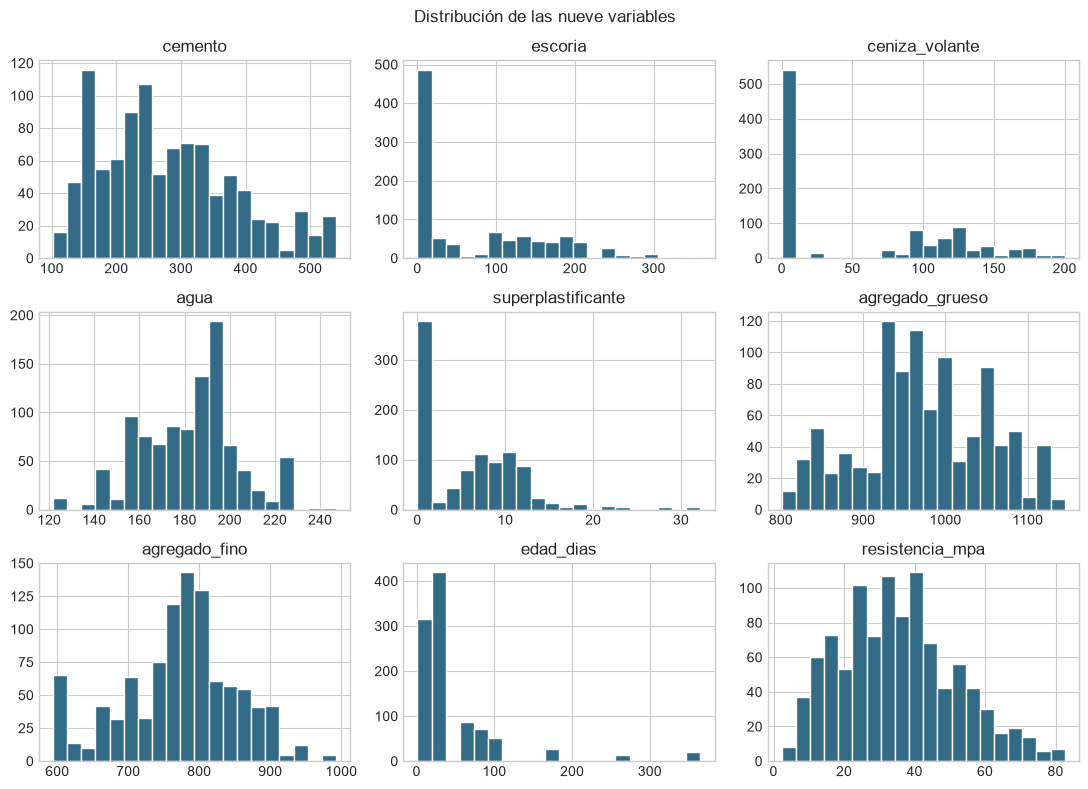

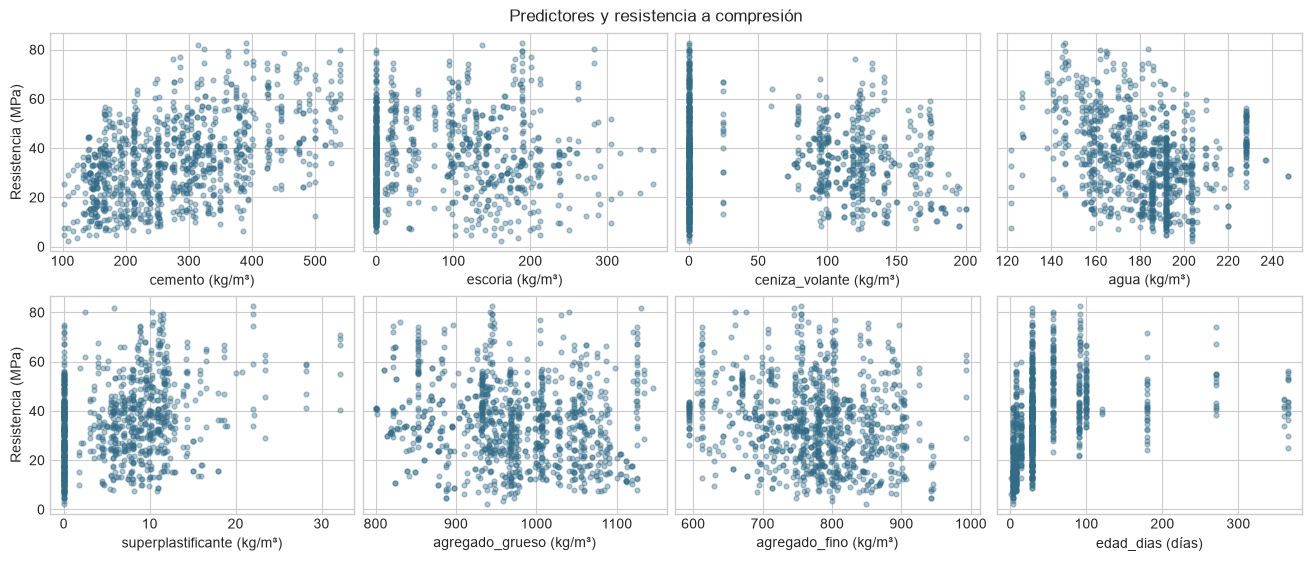

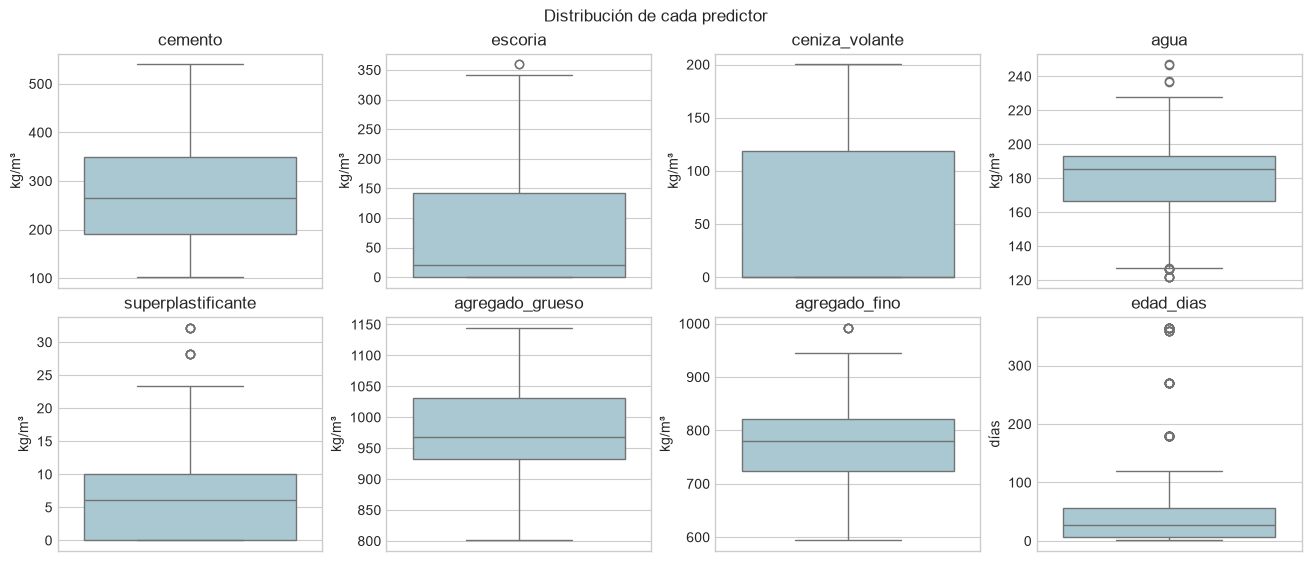

In [3]:
df.hist(bins=20, figsize=(11, 8), color="#336b87", edgecolor="white")
plt.suptitle("Distribución de las nueve variables")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 4, figsize=(13, 5.5), layout="constrained", sharey=True)
for ax, columna in zip(axes.flat, X.columns):
    unidad = "días" if columna == "edad_dias" else "kg/m³"
    ax.scatter(X[columna], y, alpha=0.38, s=12, color="#336b87")
    ax.set_xlabel(f"{columna} ({unidad})")
for ax in axes[:, 0]:
    ax.set_ylabel("Resistencia (MPa)")
fig.suptitle("Predictores y resistencia a compresión")
plt.show()

fig, axes = plt.subplots(2, 4, figsize=(13, 5.5), layout="constrained")
for ax, columna in zip(axes.flat, X.columns):
    sns.boxplot(y=X[columna], ax=ax, color="#a3cbd9")
    ax.set(title=columna, ylabel="días" if columna == "edad_dias" else "kg/m³")
fig.suptitle("Distribución de cada predictor")
plt.show()

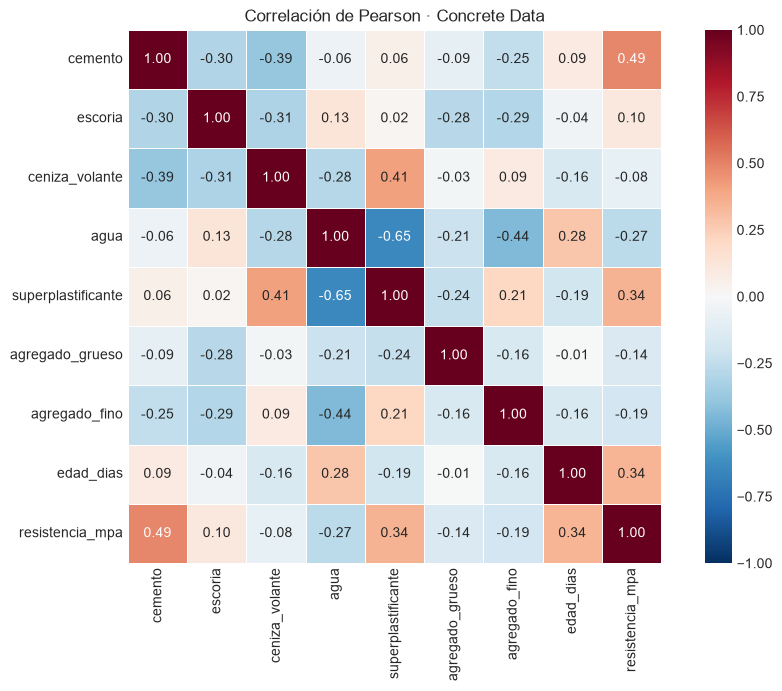

In [4]:
fig, ax = plt.subplots(figsize=(10, 6.8), layout="constrained")
corr = df.corr()
sns.heatmap(corr, annot=True, fmt=".2f", vmin=-1, vmax=1,
            cmap="RdBu_r", square=True, linewidths=0.5, ax=ax)
ax.set_title("Correlación de Pearson · Concrete Data")
plt.show()

## 3. Partición y estandarización

Se reserva el 20% de las recetas para prueba (semilla 1234). El escalador se ajusta dentro de cada pliegue de entrenamiento. La selección minimiza el RMSE medio de cinco pliegues agrupados. El ajuste final de cada kernel utiliza todo el entrenamiento. Las predicciones y ε se expresan en MPa.

In [5]:
def dividir(indices, proporcion, semilla):
    divisor = GroupShuffleSplit(n_splits=1, test_size=proporcion, random_state=semilla)
    parte_a, parte_b = next(divisor.split(X.iloc[indices], groups=grupos.iloc[indices]))
    a, b = indices[parte_a], indices[parte_b]
    assert set(grupos.iloc[a]).isdisjoint(grupos.iloc[b])
    return a, b


def mostrar_particiones(**particiones):
    display(pd.DataFrame([
        {
            "Conjunto": nombre,
            "Filas": len(indices),
            "% de filas": 100 * len(indices) / len(df),
            "Recetas": grupos.iloc[indices].nunique(),
        }
        for nombre, indices in particiones.items()
    ]).round(2))

entrenamiento, prueba = dividir(np.arange(len(df)), 0.20, 1234)
X_train, X_test = X.iloc[entrenamiento], X.iloc[prueba]
y_train, y_test = y.iloc[entrenamiento], y.iloc[prueba]
grupos_train = grupos.iloc[entrenamiento]
mostrar_particiones(Entrenamiento=entrenamiento, Prueba=prueba)

cv = GroupKFold(n_splits=5)


def buscar(kernel, rejilla, **fijos):
    estimador = make_pipeline(StandardScaler(), SVR(kernel=kernel, **fijos))
    busqueda = GridSearchCV(
        estimador, {f"svr__{k}": v for k, v in rejilla.items()},
        scoring="neg_root_mean_squared_error", cv=cv, error_score="raise",
    )
    busqueda.fit(X_train, y_train, groups=grupos_train)
    tabla = pd.DataFrame(busqueda.cv_results_["params"])
    tabla.columns = tabla.columns.str.removeprefix("svr__")
    tabla["RMSE CV (MPa)"] = -busqueda.cv_results_["mean_test_score"]
    print({k.removeprefix("svr__"): v for k, v in busqueda.best_params_.items()})
    display(tabla.sort_values("RMSE CV (MPa)").round(4).reset_index(drop=True))
    return busqueda, tabla


def diagnostico(predicho, titulo):
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), layout="constrained")
    minimo = min(y_test.min(), predicho.min())
    maximo = max(y_test.max(), predicho.max())
    axes[0].scatter(y_test, predicho, alpha=0.6, color="#336b87")
    axes[0].plot([minimo, maximo], [minimo, maximo], "--", color="#b24832")
    axes[0].set(xlabel="Observado (MPa)", ylabel="Predicho (MPa)", title="Observado frente a predicho")
    axes[1].scatter(predicho, y_test.to_numpy() - predicho, alpha=0.6, color="#336b87")
    axes[1].axhline(0, linestyle="--", color="#b24832")
    axes[1].set(xlabel="Predicho (MPa)", ylabel="Residuo (MPa)", title="Residuos en prueba")
    fig.suptitle(titulo)
    plt.show()

def medir(observado, predicho):
    mse = mean_squared_error(observado, predicho)
    return {
        "MSE (MPa²)": mse,
        "RMSE (MPa)": np.sqrt(mse),
        "MAE (MPa)": mean_absolute_error(observado, predicho),
        "R²": r2_score(observado, predicho),
    }

mezclas = pd.DataFrame([
    [300, 90, 75, 175, 7, 1000, 760, 7],
    [300, 90, 75, 175, 7, 1000, 760, 28],
    [300, 90, 75, 175, 7, 1000, 760, 90],
], columns=X.columns, index=["7 días", "28 días", "90 días"])

,Conjunto,Filas,% de filas,Recetas
0,Entrenamiento,781,77.71,342
1,Prueba,224,22.29,86


## 4. Kernel lineal

Se conserva el barrido del ejemplo sobre C. La curva muestra el RMSE de validación cruzada.

{'C': 1}


,C,RMSE CV (MPa)
0,1,10.4454
1,3,10.6407
2,5,10.6716
3,7,10.6796
4,9,10.6886
5,11,10.6956
6,13,10.7017
7,21,10.7029
8,19,10.7029
9,23,10.7052


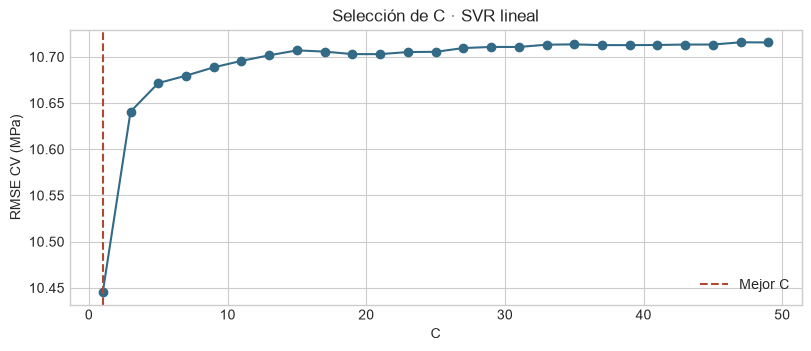

,SVR lineal
MSE (MPa²),150.9938
RMSE (MPa),12.2880
MAE (MPa),9.5339
R²,0.4654


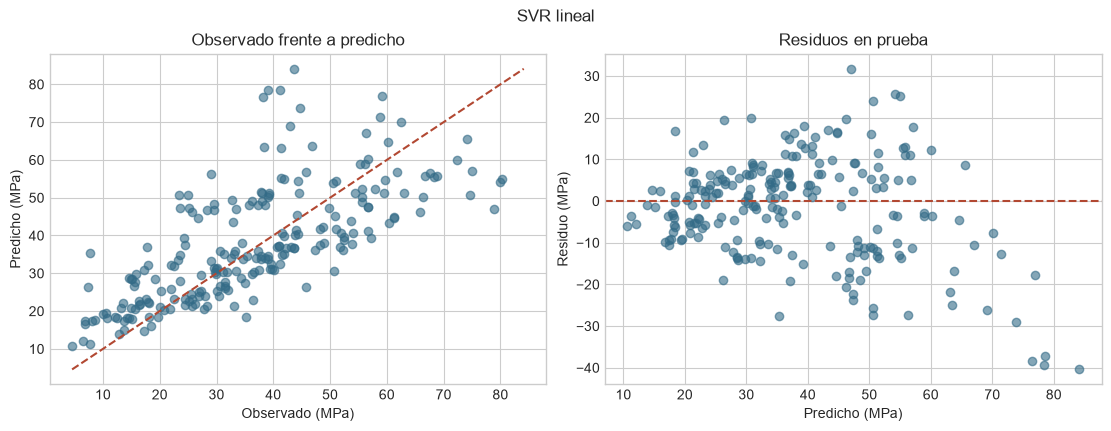

,cemento,escoria,ceniza_volante,agua,superplastificante,agregado_grueso,agregado_fino,edad_dias,prediccion_mpa
7 días,300,90,75,175,7,1000,760,7,36.56
28 días,300,90,75,175,7,1000,760,28,39.88
90 días,300,90,75,175,7,1000,760,90,49.67


In [6]:
lineal, tabla_lineal = buscar("linear", {"C": list(range(1, 50, 2))})
fig, ax = plt.subplots(figsize=(8, 3.4), layout="constrained")
ax.plot(tabla_lineal["C"], tabla_lineal["RMSE CV (MPa)"], "o-", color="#336b87")
ax.axvline(lineal.best_params_["svr__C"], color="#b24832", linestyle="--", label="Mejor C")
ax.set(xlabel="C", ylabel="RMSE CV (MPa)", title="Selección de C · SVR lineal")
ax.legend()
plt.show()

pred_lineal = lineal.predict(X_test)
display(pd.Series(medir(y_test, pred_lineal), name="SVR lineal").round(4).to_frame())
diagnostico(pred_lineal, "SVR lineal")
display(mezclas.assign(prediccion_mpa=lineal.predict(mezclas)).round(2))

## 5. Kernel polinomial

Se conserva el grado 2 y la búsqueda de C. La rejilla se amplía para explorar el ajuste con la resistencia expresada en MPa.

In [7]:
poli, _ = buscar("poly", {"C": [0.01, 0.05, 0.13, 1, 5, 15, 30, 60]}, degree=2, gamma="auto")
pred_poli = poli.predict(X_test)
display(pd.Series(medir(y_test, pred_poli), name="SVR polinomial").round(4).to_frame())
display(mezclas.assign(prediccion_mpa=poli.predict(mezclas)).round(2))

{'C': 1}


,C,RMSE CV (MPa)
0,1.00,14.6520
1,5.00,14.9848
2,15.00,15.0387
3,30.00,15.1835
4,60.00,15.2769
5,0.13,15.3001
6,0.05,15.6701
7,0.01,16.0241


,SVR polinomial
MSE (MPa²),257.4373
RMSE (MPa),16.0449
MAE (MPa),12.5073
R²,0.0886


,cemento,escoria,ceniza_volante,agua,superplastificante,agregado_grueso,agregado_fino,edad_dias,prediccion_mpa
7 días,300,90,75,175,7,1000,760,7,31.91
28 días,300,90,75,175,7,1000,760,28,31.75
90 días,300,90,75,175,7,1000,760,90,31.09


## 6. Kernel gaussiano (RBF)

Como en el ejemplo, se recorren primero C, después γ y luego ε. Se mantiene en cada etapa el valor seleccionado en la anterior. Este ajuste secuencial puede diferir del resultado de una búsqueda conjunta.

In [8]:
rbf_c, _ = buscar("rbf", {"C": [2, 5, 10, 20, 40, 80, 160, 320]}, gamma=0.125, epsilon=0.5)
c_rbf = rbf_c.best_params_["svr__C"]
rbf_gamma, _ = buscar(
    "rbf", {"gamma": [0.0019, 0.0099, 0.02, 0.05, 0.08, 0.125, 0.2, 0.35, 0.6]},
    C=c_rbf, epsilon=0.5,
)
gamma_rbf = rbf_gamma.best_params_["svr__gamma"]
rbf, _ = buscar("rbf", {"epsilon": [0.01, 0.1, 0.4, 0.5, 0.65, 1, 2]}, C=c_rbf, gamma=gamma_rbf)
pred_rbf = rbf.predict(X_test)
display(pd.Series(medir(y_test, pred_rbf), name="SVR RBF").round(4).to_frame())

{'C': 160}


,C,RMSE CV (MPa)
0,160,6.8143
1,80,6.8174
2,40,6.8686
3,320,6.9537
4,20,7.0112
5,10,7.3222
6,5,7.9319
7,2,9.0300


{'gamma': 0.08}


,gamma,RMSE CV (MPa)
0,0.0800,6.8125
1,0.1250,6.8143
2,0.0500,6.8425
3,0.2000,7.1046
4,0.0200,7.2402
5,0.3500,7.3072
6,0.0099,7.5473
7,0.6000,8.0066
8,0.0019,8.9961


{'epsilon': 2}


,epsilon,RMSE CV (MPa)
0,2.00,6.6827
1,1.00,6.7666
2,0.65,6.7890
3,0.50,6.8125
4,0.40,6.8326
5,0.10,6.8817
6,0.01,6.8921


,SVR RBF
MSE (MPa²),46.5580
RMSE (MPa),6.8233
MAE (MPa),5.0669
R²,0.8352


## 7. Kernel sigmoidal

Además de C, se prueban tres valores de γ, dado que el valor fijo del ejemplo dependía de la base original.

In [9]:
sigmoide, _ = buscar("sigmoid", {"C": [0.1, 0.5, 1, 2, 5, 10, 14], "gamma": [0.01, 0.125, 1]})
pred_sigmoide = sigmoide.predict(X_test)
display(pd.Series(medir(y_test, pred_sigmoide), name="SVR sigmoidal").round(4).to_frame())

{'C': 14, 'gamma': 0.01}


,C,gamma,RMSE CV (MPa)
0,14.0,0.010,10.3715
1,10.0,0.010,10.4286
2,5.0,0.010,10.8307
3,0.5,0.125,11.1390
4,0.1,1.000,12.3780
5,2.0,0.010,12.4140
6,1.0,0.125,12.5357
7,0.1,0.125,13.6649
8,1.0,0.010,13.7907
9,0.5,0.010,14.7523


,SVR sigmoidal
MSE (MPa²),144.7685
RMSE (MPa),12.0320
MAE (MPa),9.6657
R²,0.4875


## 8. Comparación y predicción de nuevas mezclas

El kernel se elige por el menor RMSE de validación cruzada. La tabla muestra el desempeño de cada ajuste en prueba. Las tres filas de ejemplo corresponden a una composición hipotética con distintas edades de curado.

,RMSE CV (MPa),MSE (MPa²),RMSE (MPa),MAE (MPa),R²
Kernel,,,,,
RBF,6.6827,46.5580,6.8233,5.0669,0.8352
Sigmoidal,10.3715,144.7685,12.0320,9.6657,0.4875
Lineal,10.4454,150.9938,12.2880,9.5339,0.4654
Polinomial,14.6520,257.4373,16.0449,12.5073,0.0886


,Observado (MPa),Lineal,Polinomial,RBF,Sigmoidal
0,79.99,54.22,41.85,62.15,52.49
12,43.01,69.10,42.67,43.86,64.46
16,39.36,31.15,32.93,36.80,27.41
20,41.84,54.88,42.25,41.46,52.65
21,28.24,21.36,27.65,17.51,19.92
22,8.06,17.41,25.45,3.78,16.90
23,44.21,45.37,40.11,38.51,38.40
28,37.43,30.87,40.23,39.07,33.66
35,38.41,63.42,45.17,39.91,57.14
36,30.08,25.19,37.36,31.58,26.79


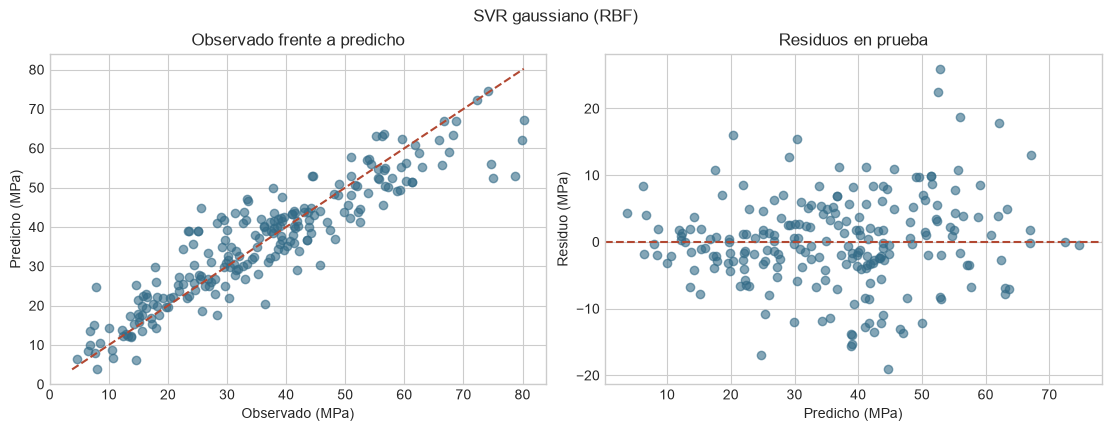

,cemento,escoria,ceniza_volante,agua,superplastificante,agregado_grueso,agregado_fino,edad_dias,prediccion_mpa
7 días,300,90,75,175,7,1000,760,7,32.79
28 días,300,90,75,175,7,1000,760,28,48.00
90 días,300,90,75,175,7,1000,760,90,67.09


Conclusión · RBF obtuvo el menor RMSE en CV (6.68 MPa).
En prueba: RMSE 6.82 MPa, MAE 5.07 MPa, R² 0.8352.


In [10]:
busquedas = {"Lineal": lineal, "Polinomial": poli, "RBF": rbf, "Sigmoidal": sigmoide}
predicciones = dict(zip(busquedas, [pred_lineal, pred_poli, pred_rbf, pred_sigmoide]))
comparacion = pd.DataFrame([
    {"Kernel": nombre, "RMSE CV (MPa)": -busquedas[nombre].best_score_,
     **medir(y_test, predicho)}
    for nombre, predicho in predicciones.items()
]).set_index("Kernel").sort_values("RMSE CV (MPa)")
display(comparacion.round(4))
display(pd.DataFrame({"Observado (MPa)": y_test, **predicciones}).head(10).round(2))

ganador = comparacion.index[0]
diagnostico(pred_rbf, "SVR gaussiano (RBF)")
if ganador not in {"RBF", "Lineal"}:
    diagnostico(predicciones[ganador], f"SVR {ganador}")
display(mezclas.assign(prediccion_mpa=busquedas[ganador].predict(mezclas)).round(2))

resultado = comparacion.loc[ganador]
print(f"Conclusión · {ganador} obtuvo el menor RMSE en CV ({resultado['RMSE CV (MPa)']:.2f} MPa).")
print(f"En prueba: RMSE {resultado['RMSE (MPa)']:.2f} MPa, "
      f"MAE {resultado['MAE (MPa)']:.2f} MPa, R² {resultado['R²']:.4f}.")